In [1]:
# Calculating feature importance of the dataset
#  Only look at the dataset with valid genres for the time being
import pandas as pd 
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction import DictVectorizer
from tqdm.auto import tqdm, trange
import matplotlib.pyplot as plt

/home/h00pyfr00d/Documents/AML_Spotify/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# normalise the dataset and create a new csv
data = pd.read_csv('data/Non-temporal/songs_with_super_genres.csv')

# find the minimum value per column, which may be negative, if its negative add that to to all numbers such that the bottom becomes zero, u want the bottom value to be zero
# find the new maximum value and divide every value the max and that will give u a scale between 0 and 1. 

# function to find the minimum value of the specified dataframe column 
def find_minimum_value(column):
    # find the minimum value
    return column.min()

# apply the function to the whole dataset

for index, row in data.iterrows():
    for col in data.select_dtypes(include=[np.number]).columns:
        # find the minimum value
        min_val = find_minimum_value(data[col])
        # shift the values to make the minimum zero
        shifted = data[col] - min_val
        # find the maximum value
        max_val = shifted.max()
        # divide by the maximum value if it's not zero
        if max_val != 0:
            data[col] = shifted / max_val

data.to_csv('../data/normalised_data.csv', index=False)


In [7]:
data = pd.read_csv('../data/normalised_data.csv')

valid_genre_data_mask = pd.isna(data['super_genre']) == False
valid_genre_data = data[valid_genre_data_mask]
valid_genre_data

# Split the data into training set 80% and test set 20%
df_train_full, df_test = train_test_split(valid_genre_data, test_size=0.2, random_state=1)
# Further split the training set into training set 75% and validation set 25%
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=1)

# train_test_split() also shuffles the data randomly before splitting
# so resetting the indexes as follows:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

#  extract the target labels (the genre column) as Numpy arrays
y_train = df_train['super_genre'].values
y_val = df_val['super_genre'].values
y_test = df_test['super_genre'].values

#  drop the target label from the data
#  for now dont include one-hot enocodings for nationality and detected language, maybe come back and include one hot encodings?
del df_train['super_genre']
del df_val['super_genre']
del df_test['super_genre']

cols = valid_genre_data.select_dtypes(include=np.number).columns.tolist()
print(cols)
#  ['Rank', 'Danceability', 'Energy', 'Speechiness', 'Acousticness', 'Instrumentalness', 'Valence', 
# 'Points (Total)', 'num_languages', 'track_popularity', 'artist_followers', 'artist_popularity', 'Loudness']

['Unnamed: 0', 'Danceability', 'Energy', 'Speechiness', 'Acousticness', 'Instrumentalness', 'Valence', 'num_languages', 'track_popularity', 'artist_followers', 'artist_popularity', 'Loudness']


In [8]:
# change the unique genres into numerical labels by numbering the super genres from 0 to n-1, n being the total number of unique super genres
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_val = le.transform(y_val)
y_test = le.transform(y_test)

#  gets the numeric feature columns and converts the resulting dataframe into a list of dictionaries, e.g., 'danceability': 0.5, 'energy': 0.8, ...
train_dicts = df_train[cols].to_dict(orient='records')

#  DictVectorizer will convert the list of dictionaries into a numeric vector similar to one-hot encoding for categorical variables, a dense Numpy array
#  fit_transform both learns the structure of waht features exists and converts the training data
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

# we do a similar thing for the validation data
val_dict = df_val[cols].to_dict(orient='records')
X_val = dv.transform(val_dict)  # only transform, don't fit again

#do the same for test data
test_dict = df_test[cols].to_dict(orient='records')
X_test = dv.transform(test_dict)  # only transform, don't fit again


In [35]:
# Feature importance using Random Forest Classifier
rf = RandomForestClassifier(random_state=1)
rf.fit(X_train, y_train)
importances = rf.feature_importances_
print(importances)

df_importances = pd.DataFrame()
df_importances['feature'] = dv.feature_names_
df_importances['importance'] = importances
df_importances.sort_values(by='importance', ascending=False, inplace=True)
print(df_importances)

[0.08224333 0.08239499 0.07888784 0.01616982 0.08496884 0.10796589
 0.05993865 0.08054758 0.19177512 0.14424942 0.00913863 0.06171989]
              feature  importance
8    artist_followers    0.191775
9   artist_popularity    0.144249
5         Speechiness    0.107966
4            Loudness    0.084969
1        Danceability    0.082395
0        Acousticness    0.082243
7             Valence    0.080548
2              Energy    0.078888
11   track_popularity    0.061720
6          Unnamed: 0    0.059939
3    Instrumentalness    0.016170
10      num_languages    0.009139


In [7]:
#print the size of train, val and test datasets
print(len(df_train))
print(len(df_val))
print(len(df_test))

3152
1051
1051


In [8]:
#Implementing a Logistic Regression Model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

#baseline lr model
lr_model = LogisticRegression(multi_class='ovr', solver='lbfgs', random_state=1)
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict_proba(X_val)
print("baseline score")
print(roc_auc_score(y_val, y_pred, multi_class='ovr'))

baseline score
0.8575345671265783


/home/h00pyfr00d/Documents/AML_Spotify/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1281: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


In [9]:
#balanced class lr model with max iterations increased
lr_model = LogisticRegression(multi_class='ovr', solver='lbfgs', random_state=1, class_weight='balanced', max_iter=550)
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict_proba(X_val)
print("balanced class score")
print(roc_auc_score(y_val, y_pred, multi_class='ovr'))
#Making the class weights balanced improved the score

/home/h00pyfr00d/Documents/AML_Spotify/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1281: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


balanced class score
0.854553107871553


In [10]:
# List of different max_iter values to try
max_iters = [600, 700, 800, 900, 1000, 1500, 2000]

# Store results
scores = []

for iters in max_iters:
    # Create and fit the logistic regression model
    lr_model = LogisticRegression(
        multi_class='ovr',
        solver='lbfgs',
        random_state=1,
        class_weight='balanced',
        max_iter=iters
    )
    lr_model.fit(X_train, y_train)
    
    # Predict probabilities on the validation set
    y_pred = lr_model.predict_proba(X_val)
    
    # Calculate ROC AUC score
    auc = roc_auc_score(y_val, y_pred, multi_class='ovr')
    
    # Append results
    scores.append((iters, auc))

# Create a DataFrame for easy inspection
df_scores = pd.DataFrame(scores, columns=['max_iter', 'auc'])
df_scores.round(3)
#Increasing the max iterations increases it a little bit

/home/h00pyfr00d/Documents/AML_Spotify/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1281: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/h00pyfr00d/Documents/AML_Spotify/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1281: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/h00pyfr00d/Documents/AML_Spotify/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1281: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/h00pyfr00d

,max_iter,auc
0,600,0.855
1,700,0.855
2,800,0.855
3,900,0.855
4,1000,0.855
5,1500,0.855
6,2000,0.855


In [11]:
#Implementing a decision tree classifier
from sklearn.tree import DecisionTreeClassifier

scores = []

for depth in [5, 7, 10, 12, 15, 17]:
    for s in [1, 5, 10, 15, 20, 500, 100, 200]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s)
        dt.fit(X_train, y_train)
        
        y_pred = dt.predict_proba(X_val)
        auc = roc_auc_score(y_val, y_pred, multi_class='ovr')
        
        scores.append((depth, s, auc))

columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

#highest score is with max_depth=7 and min_samples_leaf=20 which is 0.859

auc                                   
max_depth            5      7      10     12     15     17
min_samples_leaf                                          
1                 0.819  0.820  0.793  0.780  0.752  0.759
5                 0.803  0.827  0.824  0.809  0.805  0.803
10                0.803  0.823  0.823  0.825  0.822  0.822
15                0.818  0.850  0.858  0.855  0.855  0.855
20                0.817  0.859  0.850  0.850  0.846  0.846
100               0.829  0.847  0.846  0.846  0.846  0.846
200               0.800  0.800  0.800  0.800  0.800  0.800
500               0.773  0.773  0.773  0.773  0.773  0.773

In [12]:
# Doing a Random Forest Classifier 
# the default number of trees is 100, there is no max depth by default so the nodes are expanded until all leaves are pure
#  
rf = RandomForestClassifier(random_state=1)
rf.fit(X_train, y_train)

y_pred = rf.predict_proba(X_val)
print(f'Random Forest Classifier Score: {roc_auc_score(y_val, y_pred, multi_class="ovr")}')

# multi_class="ovr" compares every pair of classes separately.
#  for each class, it treats that class as the positive class and all other classes as the negative class.
#  Then, it calculates the AUC for each class and averages them to get the final AUC score.


# A higher AUC means the model’s predictions better distinguish between genres.
#  AUC doesn’t care if the top prediction is exactly right — it looks at how well the model ranks classes.
# AUC measures how well the model ranks the correct class higher than wrong ones
# Imbalanced datasets, or when you care about ranking / probability quality


Random Forest Classifier Score: 0.9372931748625133


In [13]:
# Tuning the hyperparameter MAX_DEPTH 
from sklearn.metrics import roc_auc_score
scores =[]

# tqdm is just for the progress bar
# d is the max depth controls how deep each tree can go
# n is the number of trees in the forest 10 to 200 in steps of 10 (201 because the upper limit is exclusive)
#  so this tests 4x20 =80 combinations of hyperparameters
for d in tqdm([5, 10, 15, 20]):
    for n in trange(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)
        auc = roc_auc_score(y_val, y_pred, multi_class='ovr')

        scores.append((d, n, auc))



100%|██████████| 4/4 [00:38<00:00,  9.55s/it]


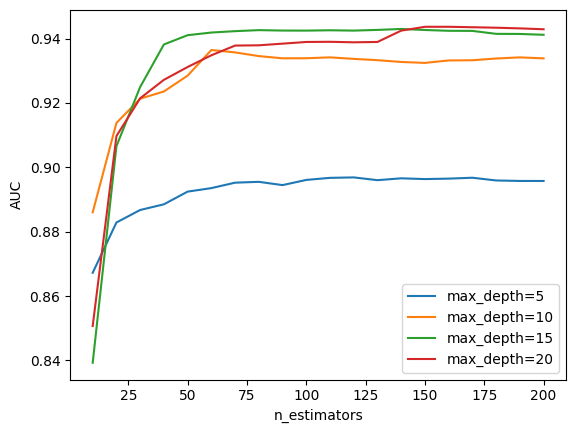

In [ ]:
# Create a dataframe to easily inspect the results of the hyperparameter tuning

columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

# plot the results for each max depth value
for d in [5, 10, 15, 20]:
    df_subset = df_scores[df_scores.max_depth == d]
    
    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.xlabel('n_estimators')
plt.ylabel('AUC')
plt.legend()

# plt.savefig("max_depth.pdf")

# Producing a plot with the max_depth=15 producing the most stable high AUC score around 0.87

In [15]:
#  Found this from previous cell
max_depth=15
# Tuning min_samples_leaf
min_samples_leaf_scores = []

for s in tqdm([1, 3, 5, 10, 50]):
    for n in trange(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)
        auc = roc_auc_score(y_val, y_pred, multi_class='ovr')

        min_samples_leaf_scores.append((s, n, auc))

100%|██████████| 5/5 [00:43<00:00,  8.77s/it]


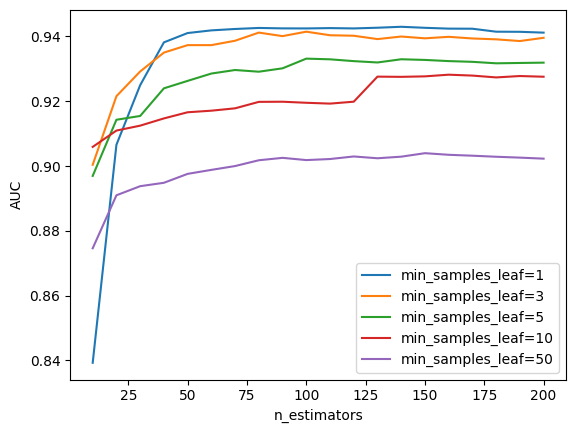

In [ ]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
min_samples_leaf_df_scores = pd.DataFrame(min_samples_leaf_scores, columns=columns)
values = [1, 3, 5, 10, 50]

for s in values:
    df_subset = min_samples_leaf_df_scores[min_samples_leaf_df_scores.min_samples_leaf == s]
    
    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='min_samples_leaf=%d' % s)

plt.xlabel('n_estimators')
plt.ylabel('AUC')
plt.legend()

# plt.savefig("min_samples_leaf.pdf")
# Producing a plot with the min_samples_leaf=10 producing the most stable high AUC score around 0.87
#  although there is no other plots for the min_samples_leaf except for min_samples_leaf=5 which is strange

In [17]:
# Final model with tuned hyperparameters
min_samples_leaf=1
n_estimators =150
max_depth=15

rf = RandomForestClassifier(n_estimators=n_estimators,
                            max_depth=max_depth,
                            min_samples_leaf=min_samples_leaf,
                            random_state=1)
rf.fit(X_train, y_train)

y_pred = rf.predict_proba(X_val)
print(f'Random Forest Classifier AUC score: {roc_auc_score(y_val, y_pred, multi_class="ovr")}')

Random Forest Classifier AUC score: 0.9426763104093913


In [18]:
# Define the parameter ranges
max_depths = [5, 10, 15, 20]
n_estimators_range = list(range(10, 201, 10))
min_samples_leaf_range = [1, 3, 5, 10, 50]

# Combined grid search
combined_scores = []

print("Testing all combinations of max_depth, n_estimators, and min_samples_leaf")
print(f"Total combinations: {len(max_depths)} × {len(n_estimators_range)} × {len(min_samples_leaf_range)} = {len(max_depths) * len(n_estimators_range) * len(min_samples_leaf_range)}")

# Use tqdm for overall progress
for d in tqdm(max_depths, desc="Max Depth"):
    for s in min_samples_leaf_range:
        for n in n_estimators_range:
            rf = RandomForestClassifier(
                n_estimators=n,
                max_depth=d,
                min_samples_leaf=s,
                random_state=1,
                n_jobs=-1  # Use all CPU cores for faster training
            )
            rf.fit(X_train, y_train)

            y_pred_rf = rf.predict(X_val)
            y_pred_rf_proba = rf.predict_proba(X_val)
            auc = roc_auc_score(y_val, y_pred_rf_proba, multi_class='ovr')

            combined_scores.append((d, s, n, auc))

# Create DataFrame for analysis
columns = ['max_depth', 'min_samples_leaf', 'n_estimators', 'auc']
df_combined = pd.DataFrame(combined_scores, columns=columns)

# Find the best combination
best_idx = df_combined['auc'].idxmax()
best_params = df_combined.loc[best_idx]

print("\n" + "="*50)
print("BEST COMBINATION FOUND:")
print(f"Max Depth: {best_params['max_depth']}")
print(f"Min Samples Leaf: {best_params['min_samples_leaf']}")
print(f"Number of Estimators: {best_params['n_estimators']}")
print(f"Best AUC Score: {best_params['auc']:.4f}")
print("="*50)

Testing all combinations of max_depth, n_estimators, and min_samples_leaf
Total combinations: 4 × 20 × 5 = 400


Max Depth: 100%|██████████| 4/4 [01:08<00:00, 17.06s/it]


BEST COMBINATION FOUND:
Max Depth: 20.0
Min Samples Leaf: 1.0
Number of Estimators: 160.0
Best AUC Score: 0.9437


In [19]:
#Implement the baseline model which only predicts the genre 'pop'
#print le classes
print("Label Encoder Classes:")
print(le.classes_)
#print the mapping of numerical labels to super genres
print("Numerical Label to Super Genre Mapping:")
for i, genre in enumerate(le.classes_):
    print(f"  {i}: {genre}")

#So pop is label 12
pop_numeric_value = 12

# Get all unique classes from the training data
classes = np.unique(y_train)
n_classes = len(classes)
print(f"Number of classes: {n_classes}")

# Create baseline probability predictions (1.0 for pop, 0.0 for others)
y_baseline_proba = np.zeros((len(y_val), n_classes))

#Create baseline predictions where each label is string pop
y_baseline = np.array([pop_numeric_value] * len(y_val))

# Set probability 1.0 for pop class (index 12) for all validation samples
y_baseline_proba[:, pop_numeric_value] = 1.0

# Calculate ROC AUC score for the baseline
baseline_auc = roc_auc_score(y_val, y_baseline_proba, multi_class='ovr')
print(f"Baseline Model (Always Predict Pop) ROC AUC Score: {baseline_auc:.4f}")


Label Encoder Classes:
['alternative' 'country' 'dance' 'electronic' 'folk' 'funk' 'hip hop'
 'indie' 'jazz' 'metal' 'other' 'performance' 'pop' 'r&b' 'rap'
 'religious' 'rock' 'soul' 'trap']
Numerical Label to Super Genre Mapping:
  0: alternative
  1: country
  2: dance
  3: electronic
  4: folk
  5: funk
  6: hip hop
  7: indie
  8: jazz
  9: metal
  10: other
  11: performance
  12: pop
  13: r&b
  14: rap
  15: religious
  16: rock
  17: soul
  18: trap
Number of classes: 19
Baseline Model (Always Predict Pop) ROC AUC Score: 0.5000


In [20]:
#Predicting the genres for the na values in the original dataset with our best Random Forest Classifier model

# Get entries where super_genre is NA
na_genre_data_mask = pd.isna(data['super_genre'])
na_genre_data = data[na_genre_data_mask]

print(f"Number of entries with NA super_genre: {len(na_genre_data)}")

# Create the best model with your optimal parameters
best_rf = RandomForestClassifier(
    n_estimators=160,
    max_depth=20,
    min_samples_leaf=1,
    random_state=1,
    n_jobs=-1
)

# Train the model on your full training data
best_rf.fit(X_train, y_train)

print("Best model trained successfully!")

# Prepare the NA data for prediction
# We need to use the same features (cols) and preprocessing as your training data
na_dicts = na_genre_data[cols].to_dict(orient='records')
X_na = dv.transform(na_dicts)  # Use the same DictVectorizer that was fitted on training data

print(f"Shape of NA features: {X_na.shape}")

# Make predictions
na_genre_predictions = best_rf.predict(X_na)
na_genre_probabilities = best_rf.predict_proba(X_na)

print("Predictions completed!")

# Convert numeric predictions back to genre names using the LabelEncoder
predicted_genres = le.inverse_transform(na_genre_predictions)

# Add the predictions to the NA data
na_genre_data['predicted_super_genre'] = predicted_genres

print("Sample of predictions:")
display(na_genre_data[['super_genre', 'predicted_super_genre']].head(50))

Number of entries with NA super_genre: 3907
Best model trained successfully!
Shape of NA features: (3907, 12)
Predictions completed!
Sample of predictions:


/tmp/ipykernel_346999/2225145446.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  na_genre_data['predicted_super_genre'] = predicted_genres


,super_genre,predicted_super_genre
3,NaN,dance
4,NaN,pop
5,NaN,pop
7,NaN,rap
8,NaN,rap
9,NaN,pop
10,NaN,pop
11,NaN,pop
12,NaN,pop
13,NaN,pop


In [21]:
# Distribution of predicted genres
predicted_genre_counts = na_genre_data['predicted_super_genre'].value_counts()
print("Predicted genre distribution:")
for genre, count in predicted_genre_counts.items():
    percentage = count / len(na_genre_data) * 100
    print(f"  {genre}: {count} predictions ({percentage:.1f}%)")

Predicted genre distribution:
  pop: 1377 predictions (35.2%)
  rap: 1052 predictions (26.9%)
  electronic: 494 predictions (12.6%)
  hip hop: 475 predictions (12.2%)
  trap: 186 predictions (4.8%)
  dance: 120 predictions (3.1%)
  other: 96 predictions (2.5%)
  rock: 56 predictions (1.4%)
  folk: 16 predictions (0.4%)
  funk: 11 predictions (0.3%)
  jazz: 7 predictions (0.2%)
  r&b: 6 predictions (0.2%)
  country: 5 predictions (0.1%)
  performance: 3 predictions (0.1%)
  soul: 2 predictions (0.1%)
  metal: 1 predictions (0.0%)


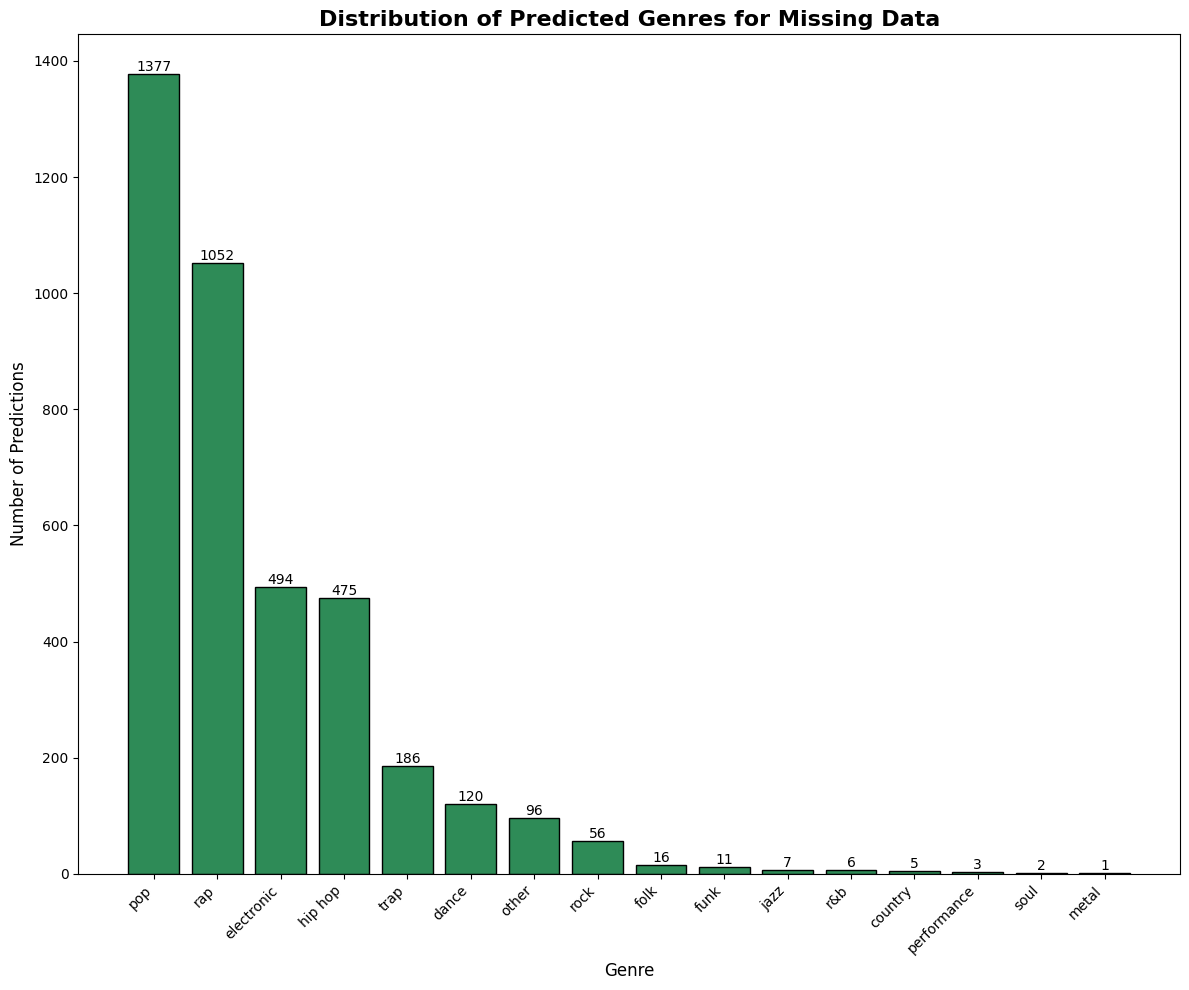

In [45]:
# Distribution of predicted genres
predicted_genre_counts = na_genre_data['predicted_super_genre'].value_counts()

# Create histogram
plt.figure(figsize=(12, 10))
bars = plt.bar(predicted_genre_counts.index, predicted_genre_counts.values, color='seagreen', edgecolor='black')

# Customize the plot
plt.title('Distribution of Predicted Genres for Missing Data', fontsize=16, fontweight='bold')
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Number of Predictions', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom')

plt.tight_layout()
plt.savefig("genres_distribution_missing_data.pdf")
plt.show()

In [23]:
#Generate a table of metrics comparing the different models
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression(
        multi_class='ovr',
        solver='lbfgs',
        random_state=1,
        class_weight='balanced',
        max_iter=900
    )
lr_model.fit(X_train, y_train)
    
# Predict probabilities on the validation set
y_pred_lr = lr_model.predict(X_val)
y_pred_lr_proba = lr_model.predict_proba(X_val)

dt = DecisionTreeClassifier(max_depth=7, min_samples_leaf=20)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_val)
y_pred_dt_proba = dt.predict_proba(X_val)

rf = RandomForestClassifier(
                n_estimators=160,
                max_depth=20,
                min_samples_leaf=1,
                random_state=1,
                n_jobs=-1  # Use all CPU cores for faster training
            )
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_val)
y_pred_rf_proba = rf.predict_proba(X_val)

/home/h00pyfr00d/Documents/AML_Spotify/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1281: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


In [24]:
# Initialize results dictionary
from sklearn.metrics import log_loss, f1_score, cohen_kappa_score, matthews_corrcoef
results = {}

results['Baseline (Always Pop)'] = {
    'Accuracy': accuracy_score(y_val, y_baseline),
    'ROC AUC': roc_auc_score(y_val, y_baseline_proba, multi_class='ovr'),
    'Log Loss': log_loss(y_val, y_baseline_proba),
    'F1-Macro': f1_score(y_val, y_baseline, average='macro'),
    'Matthews Corrcoef': matthews_corrcoef(y_val, y_baseline)
}


results['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_val, y_pred_lr),
    'ROC AUC': roc_auc_score(y_val, y_pred_lr_proba, multi_class='ovr'),
    'Log Loss': log_loss(y_val, y_pred_lr_proba),
    'F1-Macro': f1_score(y_val, y_pred_lr, average='macro'),
    'Matthews Corrcoef': matthews_corrcoef(y_val, y_pred_lr)
}

results['Decision Tree'] = {
    'Accuracy': accuracy_score(y_val, y_pred_dt),
    'ROC AUC': roc_auc_score(y_val, y_pred_dt_proba, multi_class='ovr'), 
    'Log Loss': log_loss(y_val, y_pred_dt_proba),
    'F1-Macro': f1_score(y_val, y_pred_dt, average='macro'),
    'Matthews Corrcoef': matthews_corrcoef(y_val, y_pred_dt)
}


results['Random Forest'] = {
    'Accuracy': accuracy_score(y_val, y_pred_rf),
    'ROC AUC': roc_auc_score(y_val, y_pred_rf_proba, multi_class='ovr'),
    'Log Loss': log_loss(y_val, y_pred_rf_proba),
    'F1-Macro': f1_score(y_val, y_pred_rf, average='macro'),
    'Matthews Corrcoef': matthews_corrcoef(y_val, y_pred_rf)
}

#Accuracy:  number of correct predictions divided by the total number of predictions
#ROC AUC:  measures the model's ability to distinguish between classes, with higher values indicating better performanc
#Log Loss:  takes into account the uncertainty of predictions by penalizing models more heavily for confidently incorrect predictions, with lower values indicating better performance
#F1-Macro:  harmonic mean of precision and recall, which gives each class equal importance regardless of their frequency
#Matthews Corrcoef:  takes into account true and false positives and negatives, providing a balanced measure even for imbalanced datasets

# Create comparison table
df_comparison = pd.DataFrame(results).T
print("MODEL COMPARISON TABLE")
print("=" * 80)
display(df_comparison.round(4))

MODEL COMPARISON TABLE


,Accuracy,ROC AUC,Log Loss,F1-Macro,Matthews Corrcoef
Baseline (Always Pop),0.2036,0.5000,28.7046,0.0178,0.0000
Logistic Regression,0.3444,0.8546,2.1104,0.2407,0.2767
Decision Tree,0.4891,0.8593,2.8615,0.2451,0.3976
Random Forest,0.6984,0.9437,1.1802,0.5908,0.6469


In [25]:
# Create a copy of the original data to avoid modifying the original
complete_data = data.copy()

# Fill in the missing super_genre values with predictions
na_indices = na_genre_data.index
complete_data.loc[na_indices, 'super_genre'] = predicted_genres

# Verify no missing values remain
print("Missing values after filling:")
print(f"super_genre NA count: {complete_data['super_genre'].isna().sum()}")

print(f"\nDataset sizes:")
print(f"Original data: {len(data)} rows")
print(f"Complete data: {len(complete_data)} rows")
print(f"Filled {len(na_genre_data)} missing genres")

#display(complete_data.head(50))

# Export to CSV file
complete_data.to_csv('../data/all_genres_dataset.csv', index=False)
print("Dataset exported to: data/all_genres_dataset.csv")


Missing values after filling:
super_genre NA count: 0

Dataset sizes:
Original data: 9161 rows
Complete data: 9161 rows
Filled 3907 missing genres
Dataset exported to: data/all_genres_dataset.csv


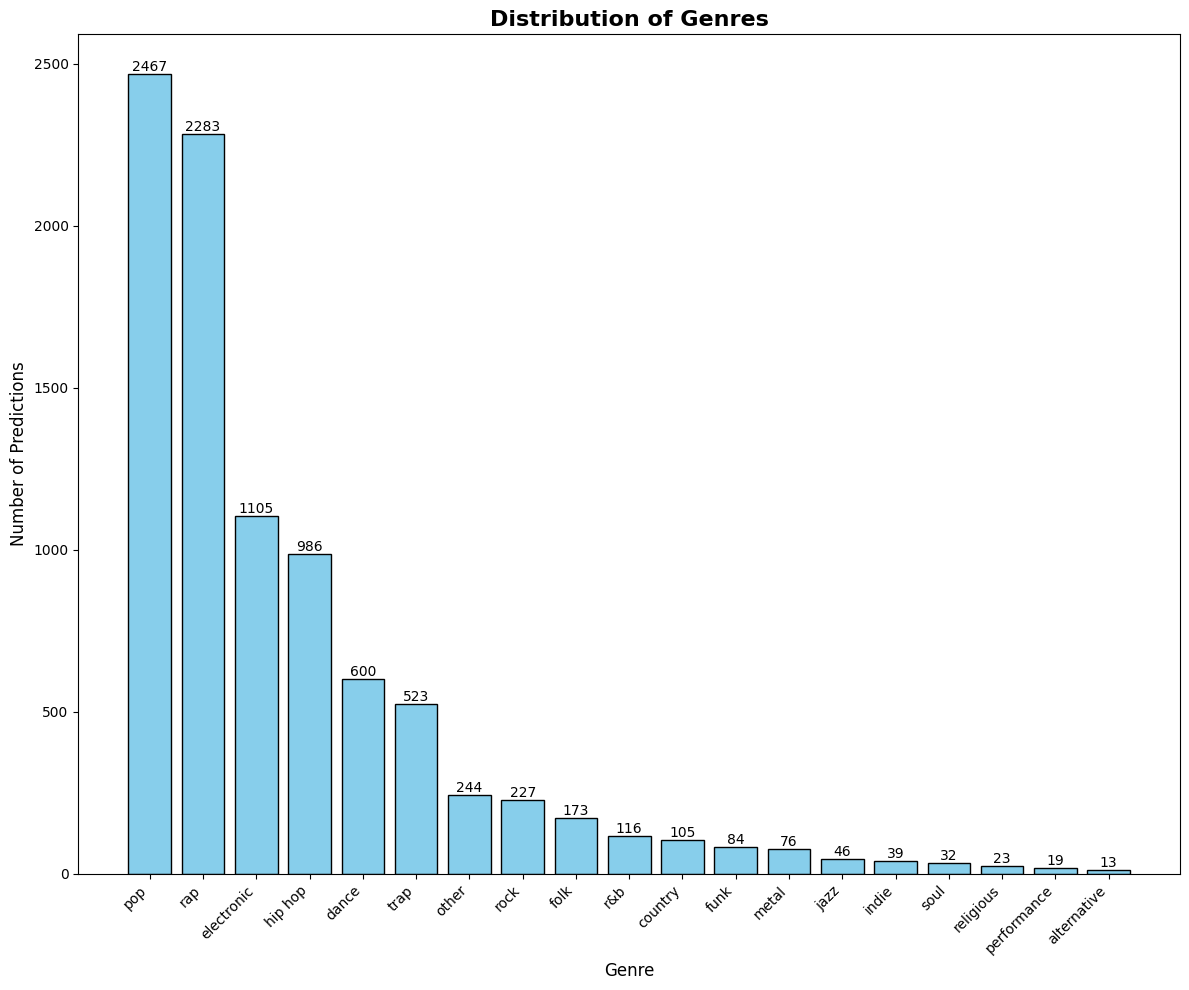

In [46]:
# Distribution of  genres
genre_counts = complete_data['super_genre'].value_counts()

# Create histogram
plt.figure(figsize=(12, 10))
bars = plt.bar(genre_counts.index, genre_counts.values, color='skyblue', edgecolor='black')

# Customize the plot
plt.title('Distribution of Genres', fontsize=16, fontweight='bold')
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Number of Predictions', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}',
             ha='center', va='bottom')

plt.tight_layout()
plt.savefig("complete_genre_distribution.pdf")
plt.show()

Predicted genre: jazz
Class probabilities (sorted):
jazz: 0.2250
pop: 0.1562
dance: 0.1500
other: 0.0938
folk: 0.0813
funk: 0.0813
electronic: 0.0688
rock: 0.0437
rap: 0.0250
performance: 0.0187
trap: 0.0125
soul: 0.0125
hip hop: 0.0125
r&b: 0.0125
alternative: 0.0063
metal: 0.0000
religious: 0.0000
indie: 0.0000
country: 0.0000


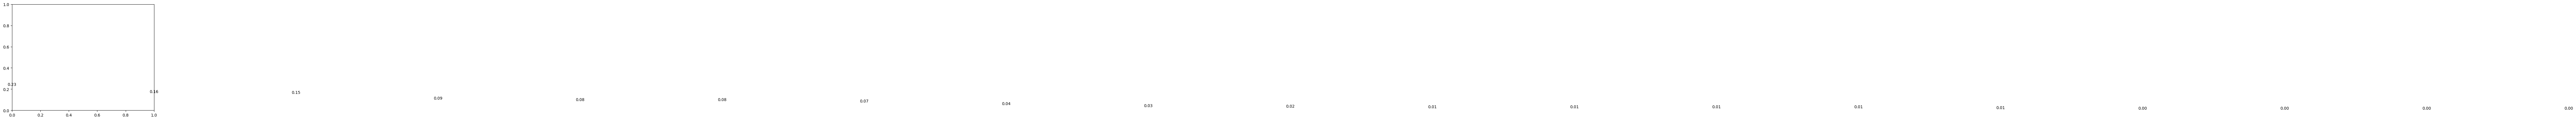

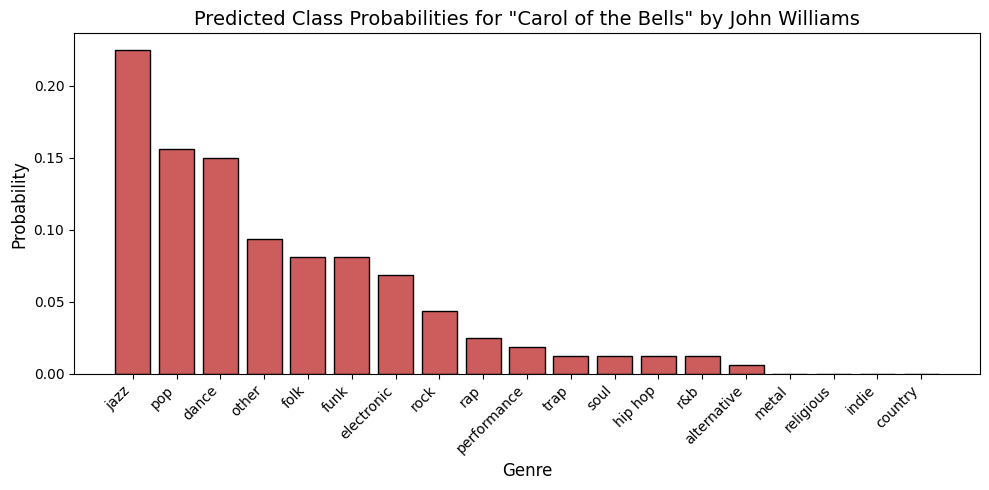

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt  # Ensure plt is imported

# Find the row for "carol of the bells" by "john williams" in valid_genre_data
song_row = valid_genre_data[
    (valid_genre_data['Title'].str.lower().str.contains('carol of the bells')) &
    (valid_genre_data['Primary Artists'].str.lower().str.contains('john williams'))
]

if not song_row.empty:
    # Prepare the feature dict for prediction
    song_dict = song_row[cols].to_dict(orient='records')
    X_song = dv.transform(song_dict)
    # Predict genre using the trained random forest model
    pred_label = rf.predict(X_song)[0]
    pred_genre = le.inverse_transform([pred_label])[0]
    pred_proba = rf.predict_proba(X_song)[0]
    # Sort probabilities from biggest to smallest
    sorted_indices = np.argsort(pred_proba)[::-1]
    sorted_genres = le.classes_[sorted_indices]
    sorted_probs = pred_proba[sorted_indices]
    # Show result
    print(f"Predicted genre: {pred_genre}")
    print("Class probabilities (sorted):")
    for genre, prob in zip(sorted_genres, sorted_probs):
        print(f"{genre}: {prob:.4f}")

    # Add probability values on top of bars
    for i, (genre, prob) in enumerate(zip(sorted_genres, sorted_probs)):
        plt.text(i, prob, f'{prob:.2f}', ha='center', va='bottom', fontsize=10)
    # Show class probabilities as a histogram
    plt.figure(figsize=(10, 5))
    plt.bar(sorted_genres, sorted_probs, color='indianred', edgecolor='black')  # Deep red with green edges for a Christmas feel
    plt.title('Predicted Class Probabilities for \"Carol of the Bells\" by John Williams', fontsize=14)
    plt.xlabel('Genre', fontsize=12)
    plt.ylabel('Probability', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('carol_of_the_bells_genre_probs.pdf')
    plt.show()
else:
    print("Song not found in the validation set.")